# Lab 07: Improving HOG-Based Medical Image Classification Using a Genetic Algorithm
**Dataset:** PneumoniaMNIST (Kaggle: `rijulshr/pneumoniamnist`, loaded with `kagglehub`) | **Baseline:** HOG + SVM | **Proposed:** GA-HOG + SVM

Runtime > Run all. CPU runtime is enough.

## Step 0: Install libraries

In [1]:
!pip install -q kagglehub scikit-image scikit-learn pandas matplotlib joblib pillow

In [2]:
import os, time, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from skimage.feature import hog
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, balanced_accuracy_score, cohen_kappa_score,
                             matthews_corrcoef, confusion_matrix)
import glob
import kagglehub
from PIL import Image
from skimage.transform import resize
from sklearn.model_selection import train_test_split

SEED = 42
rng_global = np.random.RandomState(SEED)
OUT = "results"; os.makedirs(OUT, exist_ok=True)

## 1-2. Dataset (Kaggle: rijulshr/pneumoniamnist) + fixed splits

In [3]:

path = kagglehub.dataset_download("rijulshr/pneumoniamnist")
print("Path to dataset files:", path)
for r, d, f in os.walk(path):                       # show what is inside the dataset
    print(r.replace(path, "."), "->", f[:5], "..." if len(f) > 5 else "")

SIZE = 128
def to_gray128(a):
    a = np.asarray(a)
    if a.ndim == 3 and a.shape[-1] in (3, 4): a = a[..., :3].mean(-1)
    if a.ndim == 3: a = a[..., 0]
    return resize(a.astype(np.float32), (SIZE, SIZE), anti_aliasing=True,
                  preserve_range=True).astype(np.float32)

npz_files = glob.glob(os.path.join(path, "**", "*.npz"), recursive=True)
if npz_files:                                        # MedMNIST .npz format
    npz_files.sort(key=lambda p: ("128" not in p, len(p)))
    d = np.load(npz_files[0])
    print("Using:", npz_files[0], "| keys:", list(d.keys()))
    def get(s):
        X = np.array(Parallel(n_jobs=-1)(delayed(to_gray128)(i) for i in d[f"{s}_images"]))
        return X, d[f"{s}_labels"].ravel()
    Xtr_img, ytr = get("train"); Xva_img, yva = get("val"); Xte_img, yte = get("test")
else:                                                # image-folder format: split/class/img.png
    files = [f for f in glob.glob(os.path.join(path, "**", "*"), recursive=True)
             if f.lower().endswith((".png", ".jpg", ".jpeg"))]
    def split_of(f):
        parts = [p.lower() for p in os.path.relpath(f, path).split(os.sep)]
        for p in parts:
            if p in ("train", "training"): return "train"
            if p in ("val", "valid", "validation"): return "val"
            if p in ("test", "testing"): return "test"
    def load_img(f): return to_gray128(Image.open(f).convert("L"))
    data = {"train": [], "val": [], "test": []}
    for f in files:
        s = split_of(f)
        if s: data[s].append(f)
    classes = sorted({os.path.basename(os.path.dirname(f)) for s in data for f in data[s]})
    cmap = {c: i for i, c in enumerate(classes)}; print("Classes:", cmap)
    def get(s):
        X = np.array(Parallel(n_jobs=-1)(delayed(load_img)(f) for f in data[s]))
        y = np.array([cmap[os.path.basename(os.path.dirname(f))] for f in data[s]])
        return X, y
    Xtr_img, ytr = get("train"); Xva_img, yva = get("val"); Xte_img, yte = get("test")
    if len(yva) < 100:                               # tiny/no val set -> make a fixed val split
        Xtr_img, Xva_img, ytr, yva = train_test_split(
            Xtr_img, ytr, test_size=0.15, stratify=ytr, random_state=SEED)


N_TRAIN = None
if N_TRAIN and N_TRAIN < len(ytr):
    sel, _ = train_test_split(np.arange(len(ytr)), train_size=N_TRAIN,
                              stratify=ytr, random_state=SEED)
    sel = np.sort(sel); Xtr_img, ytr = Xtr_img[sel], ytr[sel]
print("Train/Val/Test sizes:", len(ytr), len(yva), len(yte))
print("Class counts (train):", dict(zip(*np.unique(ytr, return_counts=True))))

100%|██████████| 3.39M/3.39M [00:01<00:00, 2.94MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/rijulshr/pneumoniamnist/versions/1
. -> ['pneumoniamnist.npz'] 
Using: /root/.cache/kagglehub/datasets/rijulshr/pneumoniamnist/versions/1/pneumoniamnist.npz | keys: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']


Train/Val/Test sizes: 3882 524 624
Class counts (train): {np.uint8(0): np.int64(388), np.uint8(1): np.int64(3494)}


## 3-4. HOG features (Table 1 parameters)

In [4]:

def hog_one(img):
    g = img.mean(axis=2) if img.ndim == 3 else img       # grayscale
    return hog(g, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2),
               block_norm="L2-Hys").astype(np.float32)

def extract(imgs):
    return np.array(Parallel(n_jobs=-1)(delayed(hog_one)(i) for i in imgs))

t0 = time.time()
Xtr, Xva, Xte = extract(Xtr_img), extract(Xva_img), extract(Xte_img)
t_hog = time.time() - t0
N_FEAT = Xtr.shape[1]
print("HOG features per image:", N_FEAT, f"({t_hog:.1f}s)")

HOG features per image: 8100 (45.6s)


## Metrics

In [5]:

def all_metrics(y, p):
    cm = confusion_matrix(y, p)
    tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    tn = cm.sum() - (tp + fp + fn)
    spec = np.mean(tn / (tn + fp))
    return {
        "Accuracy (%)": 100 * accuracy_score(y, p),
        "Precision (Macro, %)": 100 * precision_score(y, p, average="macro", zero_division=0),
        "Recall (Macro, %)": 100 * recall_score(y, p, average="macro", zero_division=0),
        "Macro-F1 (%)": 100 * f1_score(y, p, average="macro"),
        "Weighted-F1 (%)": 100 * f1_score(y, p, average="weighted"),
        "Balanced accuracy (%)": 100 * balanced_accuracy_score(y, p),
        "Specificity (Macro, %)": 100 * spec,
        "Cohen's kappa": cohen_kappa_score(y, p),
        "Matthews corr. coeff.": matthews_corrcoef(y, p),
    }

## Baseline: tune C on validation

In [6]:

t0 = time.time()
best = (-1, None)
for C in [1, 10]:
    m = SVC(kernel="rbf", C=C, gamma="scale").fit(Xtr, ytr)
    f1 = f1_score(yva, m.predict(Xva), average="macro")
    print(f"Baseline C={C}: val macro-F1={f1:.4f}")
    if f1 > best[0]: best = (f1, C)
C_BEST = best[1]
base_model = SVC(kernel="rbf", C=C_BEST, gamma="scale").fit(Xtr, ytr)
t_base_train = time.time() - t0
t0 = time.time(); pred_base_te = base_model.predict(Xte); t_base_pred = time.time() - t0
base_val_f1 = f1_score(yva, base_model.predict(Xva), average="macro")

Baseline C=1: val macro-F1=0.9135
Baseline C=10: val macro-F1=0.9394


## 5-6. Genetic Algorithm

In [10]:

ALPHA = 0.1

sub = rng_global.choice(len(ytr), size=1500, replace=False)
Xtr_ga, ytr_ga = Xtr[sub], ytr[sub]

def fitness(mask, cache):
    key = mask.tobytes()
    if key in cache: return cache[key]
    if mask.sum() == 0: return -1.0
    m = SVC(kernel="rbf", C=C_BEST, gamma="scale").fit(Xtr_ga[:, mask], ytr_ga)
    f1 = f1_score(yva, m.predict(Xva[:, mask]), average="macro")
    fit = f1 - ALPHA * mask.sum() / N_FEAT
    cache[key] = fit
    return fit

def run_ga(pop_size, p_mut, p_cx=0.8, gens=7, elite=2, k=3, seed=SEED):
    rng = np.random.RandomState(seed); cache = {}
    pop = rng.rand(pop_size, N_FEAT) < 0.5
    hist_best, hist_mean, hist_nfeat = [], [], []
    for g in range(gens):
        fits = np.array([fitness(ind, cache) for ind in pop])
        order = np.argsort(-fits)
        hist_best.append(fits[order[0]]); hist_mean.append(fits.mean())
        hist_nfeat.append(int(pop[order[0]].sum()))
        print(f"  gen {g+1:2d}/{gens} best={fits[order[0]]:.4f} mean={fits.mean():.4f} "
              f"features={hist_nfeat[-1]}")
        new = [pop[i].copy() for i in order[:elite]]             # elitism
        while len(new) < pop_size:

            def pick():
                c = rng.choice(pop_size, k, replace=False); return pop[c[np.argmax(fits[c])]]
            p1, p2 = pick(), pick()
            if rng.rand() < p_cx:
                sel = rng.rand(N_FEAT) < 0.5
                c1 = np.where(sel, p1, p2); c2 = np.where(sel, p2, p1)
            else:
                c1, c2 = p1.copy(), p2.copy()
            for c in (c1, c2):
                flip = rng.rand(N_FEAT) < p_mut
                c[flip] = ~c[flip]
                new.append(c)
        pop = np.array(new[:pop_size])
    fits = np.array([fitness(ind, cache) for ind in pop])
    b = np.argmax(fits)
    return pop[b], fits[b], hist_best, hist_mean, hist_nfeat

GA_SETTINGS = {
    "GA-A (pop=20, mut=0.01)": dict(pop_size=20, p_mut=0.01),
    "GA-B (pop=30, mut=0.03)": dict(pop_size=30, p_mut=0.03),
}
ga_res = {}
for name, cfg in GA_SETTINGS.items():
    print("Running", name)
    t0 = time.time()
    mask, fit, hb, hm, hn = run_ga(**cfg)
    ga_res[name] = dict(mask=mask, fit=fit, hb=hb, hm=hm, hn=hn, time=time.time() - t0)

Running GA-A (pop=20, mut=0.01)
  gen  1/7 best=0.8634 mean=0.8522 features=3903
  gen  2/7 best=0.8634 mean=0.8561 features=3903
  gen  3/7 best=0.8634 mean=0.8586 features=3903
  gen  4/7 best=0.8635 mean=0.8590 features=3899
  gen  5/7 best=0.8665 mean=0.8611 features=3894
  gen  6/7 best=0.8692 mean=0.8633 features=3906
  gen  7/7 best=0.8719 mean=0.8658 features=3883
Running GA-B (pop=30, mut=0.03)
  gen  1/7 best=0.8634 mean=0.8524 features=3903
  gen  2/7 best=0.8666 mean=0.8555 features=4079
  gen  3/7 best=0.8674 mean=0.8579 features=3976
  gen  4/7 best=0.8676 mean=0.8598 features=3957
  gen  5/7 best=0.8684 mean=0.8613 features=3975
  gen  6/7 best=0.8684 mean=0.8617 features=3975
  gen  7/7 best=0.8711 mean=0.8635 features=3951


## Model selection on VALIDATION only

In [11]:

rows = []
for name, r in ga_res.items():
    m = SVC(kernel="rbf", C=C_BEST, gamma="scale").fit(Xtr[:, r["mask"]], ytr)
    r["val_f1"] = f1_score(yva, m.predict(Xva[:, r["mask"]]), average="macro")
    r["n_feat"] = int(r["mask"].sum())
    rows.append([name, r["n_feat"], r["val_f1"] * 100, r["fit"], r["time"]])
sel_df = pd.DataFrame(rows, columns=["GA setting", "#features", "Val macro-F1 (%)",
                                     "Best fitness", "GA time (s)"])
print(sel_df)
sel_df.to_csv(f"{OUT}/table_ga_settings.csv", index=False)
best_name = max(ga_res, key=lambda n: ga_res[n]["val_f1"])
mask = ga_res[best_name]["mask"]
print("Selected GA setting (by validation):", best_name)

                GA setting  #features  Val macro-F1 (%)  Best fitness  \
0  GA-A (pop=20, mut=0.01)       3913         93.170927      0.872013   
1  GA-B (pop=30, mut=0.03)       3951         94.499293      0.871090   

   GA time (s)  
0   604.088930  
1   931.894518  
Selected GA setting (by validation): GA-B (pop=30, mut=0.03)


## 7. Final GA-HOG SVM

In [12]:

t0 = time.time()
ga_model = SVC(kernel="rbf", C=C_BEST, gamma="scale").fit(Xtr[:, mask], ytr)
t_ga_train = time.time() - t0
t0 = time.time(); pred_ga_te = ga_model.predict(Xte[:, mask]); t_ga_pred = time.time() - t0

## 8. FINAL TEST evaluation (only now)

In [13]:

mb, mg = all_metrics(yte, pred_base_te), all_metrics(yte, pred_ga_te)
tab2 = pd.DataFrame({"HOG + SVM (Baseline)": mb, "GA-HOG + SVM (Proposed)": mg})
tab2["Improvement"] = tab2.iloc[:, 1] - tab2.iloc[:, 0]
tab2 = tab2.round(3)
tab2.to_csv(f"{OUT}/table2_main_comparison.csv")
print("\nTable 2 (TEST set)\n", tab2)

tab3 = pd.DataFrame({
    "Metric": ["#Features", "SVM train time (s)", "Test predict time (s)",
               "GA search time (s)", "Total time (s)"],
    "HOG + SVM": [N_FEAT, t_base_train, t_base_pred, 0, t_base_train + t_base_pred],
    "GA-HOG + SVM": [int(mask.sum()), t_ga_train, t_ga_pred, ga_res[best_name]["time"],
                     t_ga_train + t_ga_pred + sum(r["time"] for r in ga_res.values())],
}).round(3)
tab3.to_csv(f"{OUT}/table3_time_features.csv", index=False)
print("\nTable 3\n", tab3)


Table 2 (TEST set)
                         HOG + SVM (Baseline)  GA-HOG + SVM (Proposed)  \
Accuracy (%)                          77.083                   77.244   
Precision (Macro, %)                  86.091                   86.654   
Recall (Macro, %)                     69.530                   69.658   
Macro-F1 (%)                          70.371                   70.520   
Weighted-F1 (%)                       73.897                   74.040   
Balanced accuracy (%)                 69.530                   69.658   
Specificity (Macro, %)                69.530                   69.658   
Cohen's kappa                          0.444                    0.447   
Matthews corr. coeff.                  0.531                    0.537   

                        Improvement  
Accuracy (%)                  0.160  
Precision (Macro, %)          0.563  
Recall (Macro, %)             0.128  
Macro-F1 (%)                  0.149  
Weighted-F1 (%)               0.143  
Balanced accuracy (%

## 9. Plots

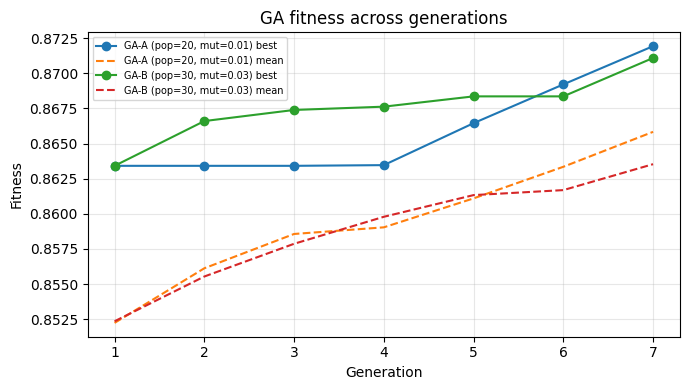

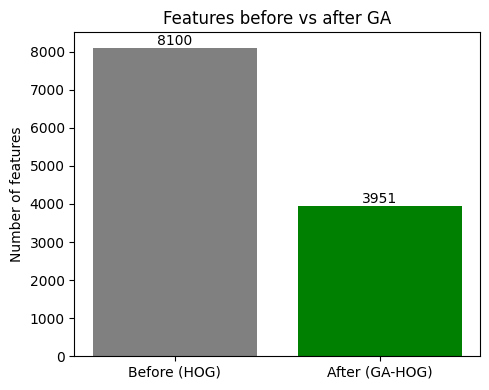

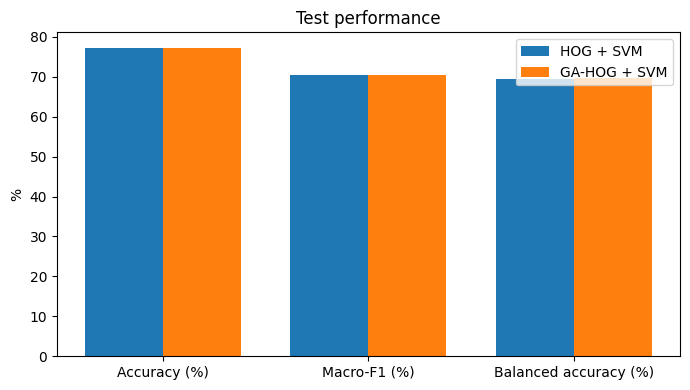


Done. HOG extraction time: 45.6s. Files saved in ./results/


In [14]:
# ---------------- 9. Plots ----------------
plt.figure(figsize=(7, 4))
for name, r in ga_res.items():
    plt.plot(range(1, len(r["hb"]) + 1), r["hb"], marker="o", label=f"{name} best")
    plt.plot(range(1, len(r["hm"]) + 1), r["hm"], "--", label=f"{name} mean")
plt.xlabel("Generation"); plt.ylabel("Fitness"); plt.title("GA fitness across generations")
plt.legend(fontsize=7); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(f"{OUT}/ga_fitness.png", dpi=150); plt.show()

plt.figure(figsize=(5, 4))
plt.bar(["Before (HOG)", "After (GA-HOG)"], [N_FEAT, int(mask.sum())], color=["gray", "green"])
for i, v in enumerate([N_FEAT, int(mask.sum())]): plt.text(i, v, str(v), ha="center", va="bottom")
plt.ylabel("Number of features"); plt.title("Features before vs after GA")
plt.tight_layout(); plt.savefig(f"{OUT}/feature_count.png", dpi=150); plt.show()

plt.figure(figsize=(7, 4)); w = .38
ks = ["Accuracy (%)", "Macro-F1 (%)", "Balanced accuracy (%)"]
x = np.arange(len(ks))
plt.bar(x - w/2, [mb[k] for k in ks], w, label="HOG + SVM")
plt.bar(x + w/2, [mg[k] for k in ks], w, label="GA-HOG + SVM")
plt.xticks(x, ks); plt.ylabel("%"); plt.legend(); plt.title("Test performance")
plt.tight_layout(); plt.savefig(f"{OUT}/performance_bar.png", dpi=150); plt.show()

print(f"\nDone. HOG extraction time: {t_hog:.1f}s. Files saved in ./{OUT}/")